# G14 — Atelier 1 : calcul du KPI de décision K1

**Ce que fait ce notebook.** Il calcule les indicateurs de la fiche `G14_Atelier1_KPI.md`, qui éclairent une décision du SDIS 33 : faut-il avancer le renfort des sapeurs-pompiers saisonniers au 1er juin, au 15 juin, ou le garder sur juillet-août ?
Le KPI de décision est **K1** : le nombre de départs de feu par jour en juin, rapporté au nombre de départs par jour en juillet-août, en %. Territoire de référence : Gironde (33), campagnes 2021-2025.

**Sources** (téléchargées par le notebook dans `atelier/data/`, dossier non commité) :
- **BDIFF**, base des incendies de forêt en France (ministère de l'Agriculture, site IGN) : un feu par ligne, avec sa commune de départ, sa date de première alerte et sa surface parcourue. Export des départements 33 et 40.
- **Code officiel géographique (COG) 2026 de l'Insee** : liste des communes au 1er janvier 2026 et mouvements de communes (fusions…), pour rapporter chaque feu à sa commune actuelle.

**Comment le relancer.** Depuis le dossier `atelier/` :
```
pip install pandas requests certifi matplotlib jinja2
```
puis « Exécuter tout » (`jinja2` sert à l'affichage des tableaux avec `df.style`). Les fichiers déjà téléchargés ne sont pas retéléchargés.

On importe les bibliothèques, on prépare les dossiers `data/` (sources) et `figures/` (graphiques PNG), et on fixe un style sobre pour les graphiques : deux couleurs, un bleu et un orange.

In [1]:
import hashlib, io, ssl, zipfile
from pathlib import Path
import certifi, requests
import pandas as pd
import matplotlib.pyplot as plt

DATA, FIGURES = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
UA = {"User-Agent": "feu-gironde-kpi/0.1 (projet pedagogique)"}
BLEU, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": "#e0e0e0", "axes.axisbelow": True})

def fr(x, decimales=1):
    """Écrit un nombre à la française : 34.44 -> '34,4'."""
    return f"{x:.{decimales}f}".replace(".", ",")

On télécharge les deux fichiers du COG 2026 utiles à la jointure (fiche 06) : les communes au 1er janvier 2026 et les mouvements de communes.

In [2]:
for fichier in ["v_commune_2026.csv", "v_mvt_commune_2026.csv"]:
    if not (DATA / fichier).exists():
        r = requests.get(f"https://www.insee.fr/fr/statistiques/fichier/8740222/{fichier}", headers=UA, timeout=120)
        r.raise_for_status()
        (DATA / fichier).write_bytes(r.content)

On exporte la BDIFF (départements 33 et 40, alertes du 01/01/2006 au 31/12/2025) comme dans la fiche 01 : une recherche, puis le zip. Le serveur présente une chaîne TLS incomplète (obstacle O03) : on ajoute au magasin `certifi` l'intermédiaire officiel HARICA, téléchargé à son adresse AIA ; la vérification TLS reste active.
Si l'export échoue, déposer à la main `Incendies.csv` dans `atelier/data/` : la cellule ne le retélécharge pas. L'empreinte SHA-256 doit valoir `00787e13…` (fiche 01).

In [3]:
csv_bdiff = DATA / "Incendies.csv"
if not csv_bdiff.exists():
    intermediaire_der = requests.get("http://crt.harica.gr/HARICA-GEANT-TLS-R1.cer", timeout=60).content
    magasin_ca = DATA / "ca_bdiff.pem"
    magasin_ca.write_text(Path(certifi.where()).read_text() + ssl.DER_cert_to_PEM_cert(intermediaire_der))
    session = requests.Session()
    session.headers.update(UA)
    session.verify = str(magasin_ca)
    recherche = {"if[dateAlerteDeb][date]": "01/01/2006", "if[dateAlerteFin][date]": "31/12/2025",
                 "if[deprts][value]": "33,40", "if[submit]": ""}
    session.get("https://bdiff.agriculture.gouv.fr/incendies", params=recherche, timeout=300).raise_for_status()
    archive = session.get("https://bdiff.agriculture.gouv.fr/incendies/zip", timeout=600)
    archive.raise_for_status()
    zipfile.ZipFile(io.BytesIO(archive.content)).extract("Incendies.csv", DATA)
print("SHA-256 du CSV :", hashlib.sha256(csv_bdiff.read_bytes()).hexdigest())

SHA-256 du CSV : 00787e13052709c61cdd3562b4e4fb6be66c4513281e4d345f10eb66557e9854


On lit le CSV de la BDIFF (3 lignes de métadonnées avant l'en-tête, séparateur `;`) en gardant les codes en texte, on convertit la surface de m² en hectares, et on vérifie que le couple (Année, Numéro) identifie bien chaque feu.

In [4]:
feux = pd.read_csv(csv_bdiff, sep=";", skiprows=3, dtype={"Département": str, "Code INSEE": str})
feux["date_alerte"] = pd.to_datetime(feux["Date de première alerte"])
feux["surface_ha"] = feux["Surface parcourue (m2)"] / 10_000
print(len(feux), "feux ; (Année, Numéro) unique :", not feux.duplicated(["Année", "Numéro"]).any())

5460 feux ; (Année, Numéro) unique : True


On rapporte chaque code INSEE à sa commune 2026 : un code absent du COG 2026 suit ses mouvements (fusions…), du plus récent, jusqu'à une commune 2026. On récupère ensuite le département 2026 de la commune.

In [5]:
communes_2026 = pd.read_csv(DATA / "v_commune_2026.csv", dtype=str).query("TYPECOM == 'COM'")[["COM", "DEP"]]
mouvements = pd.read_csv(DATA / "v_mvt_commune_2026.csv", dtype=str)
mouvements = mouvements.query("TYPECOM_AV == 'COM' and TYPECOM_AP == 'COM' and COM_AV != COM_AP"
                              " and not COM_AV.isin(@communes_2026.COM)")
commune_suivante = (mouvements.sort_values("DATE_EFF").drop_duplicates("COM_AV", keep="last")
                    .set_index("COM_AV")["COM_AP"])
feux["commune_2026"] = feux["Code INSEE"]
for _ in range(5):  # suit les fusions successives (A -> B, puis B -> C)
    feux["commune_2026"] = feux["commune_2026"].map(commune_suivante).fillna(feux["commune_2026"])
feux = feux.merge(communes_2026.rename(columns={"COM": "commune_2026", "DEP": "departement_2026"}),
                  on="commune_2026", how="left")

On garde les campagnes 2021-2025, on compte les lignes de Gironde, les codes qui ont changé à la jointure, et les lignes perdues avec leur motif.

In [6]:
feux_2021_2025 = feux[feux["Année"].between(2021, 2025)].copy()
lignes_gironde = feux_2021_2025[feux_2021_2025["Département"] == "33"]
codes_rattaches = lignes_gironde[lignes_gironde["Code INSEE"] != lignes_gironde["commune_2026"]]
perdues_non_rattachees = lignes_gironde["departement_2026"].isna().sum()
perdues_hors_gironde = (lignes_gironde["departement_2026"].notna() & (lignes_gironde["departement_2026"] != "33")).sum()
print("Lignes Gironde 2021-2025 :", len(lignes_gironde))
print("Perdues, code non rattaché :", perdues_non_rattachees, "; perdues, commune 2026 hors Gironde :", perdues_hors_gironde)
print("Codes disparus rattachés par le COG :")
print(codes_rattaches[["Année", "Code INSEE", "commune_2026"]].to_string(index=False))

Lignes Gironde 2021-2025 : 571
Perdues, code non rattaché : 0 ; perdues, commune 2026 hors Gironde : 0
Codes disparus rattachés par le COG :
 Année Code INSEE commune_2026
  2022      33409        33008


On classe chaque feu dans sa période (juin ou juillet-août) selon sa date de première alerte ; les feux des autres mois ne servent pas.

La fonction `ratio_juin_juillet_aout` calcule, pour chaque année, un total en juin et en juillet-août (nombre de départs ou surface), puis le **ratio journalier** : (total de juin ÷ 30 jours) ÷ (total de juillet-août ÷ 62 jours) × 100. Diviser par le nombre de jours rend comparables un mois de 30 jours et une période de 62 jours. Elle sert pour K1 (départs) et pour K2 (surface).

In [7]:
feux_2021_2025["periode"] = feux_2021_2025["date_alerte"].dt.month.map({6: "juin", 7: "juillet_aout", 8: "juillet_aout"})
feux_2021_2025["annee"] = feux_2021_2025["date_alerte"].dt.year

def ratio_juin_juillet_aout(feux_du_territoire, agregation):
    """agregation = "size" : nombre de départs ; "sum" : surface brûlée (ha)."""
    t = feux_du_territoire.pivot_table(index="annee", columns="periode", values="surface_ha",
                                       aggfunc=agregation).fillna(0)
    t["juin_par_jour"] = t["juin"] / 30
    t["juillet_aout_par_jour"] = t["juillet_aout"] / 62
    t["ratio"] = t["juin_par_jour"] / t["juillet_aout_par_jour"] * 100
    return t

On calcule K1 pour chaque année sur la Gironde (communes 2026 du département 33), puis la moyenne et la médiane des cinq années.

In [8]:
feux_gironde = feux_2021_2025[feux_2021_2025["departement_2026"] == "33"]
k1 = ratio_juin_juillet_aout(feux_gironde, "size")
k1_resume = pd.concat([k1, k1.agg(["mean", "median"]).rename(index={"mean": "Moyenne", "median": "Médiane"})])
part_annee_forte = k1["juin"].max() / k1["juin"].sum() * 100
annee_forte = k1["juin"].idxmax()

Ce tableau montre, pour la **Gironde**, les départs de juin et de juillet-août, la base (départs par jour en juillet-août) et K1, année par année. Les départs par jour gardent deux décimales (valeurs inférieures à 3).

In [9]:
tableau_k1 = k1_resume[["juin", "juillet_aout", "juillet_aout_par_jour", "ratio"]].rename(columns={
    "juin": "Départs en juin", "juillet_aout": "Départs en juillet-août",
    "juillet_aout_par_jour": "Départs par jour en juillet-août (base)", "ratio": "K1 (%)"})
tableau_k1.index.name = "Année"
style_k1 = (tableau_k1.style
            .format(lambda x: f"{x:g}".replace(".", ","), subset=["Départs en juin", "Départs en juillet-août"])
            .format(precision=2, decimal=",", subset=["Départs par jour en juillet-août (base)"])
            .format(precision=1, decimal=",", subset=["K1 (%)"]))
print(f"Part des départs de juin due à l'année la plus forte ({annee_forte}) : {fr(part_annee_forte)} %")
style_k1

Part des départs de juin due à l'année la plus forte (2022) : 40,4 %


periode,Départs en juin,Départs en juillet-août,Départs par jour en juillet-août (base),K1 (%)
Année,,,,
2021,2,12,"0,19","34,4"
2022,23,148,"2,39","32,1"
2023,17,31,"0,50","113,3"
2024,4,19,"0,31","43,5"
2025,11,87,"1,40","26,1"
Moyenne,"11,4","59,4","0,96","49,9"
Médiane,11,31,"0,50","34,4"


Ce graphique montre K1 par année en **Gironde** : chaque barre compare un jour de juin à un jour de juillet-août ; le chiffre au-dessus est le nombre brut de départs en juin. La ligne orange est la médiane, la ligne pointillée marque l'égalité entre juin et juillet-août.

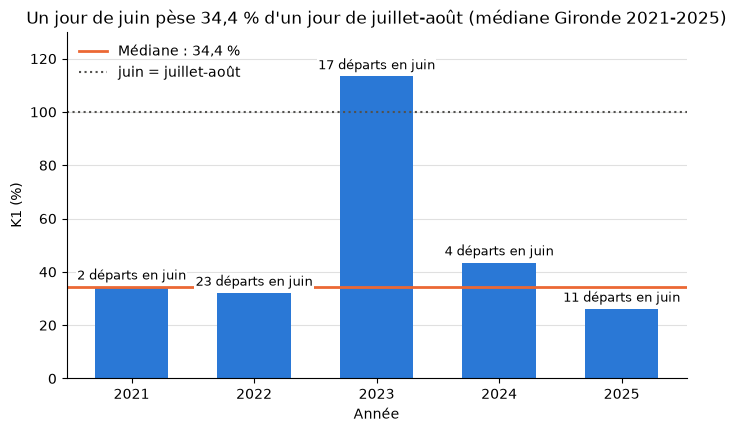

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
barres = ax.bar(k1.index.astype(str), k1["ratio"], color=BLEU, width=0.6)
etiquettes = ax.bar_label(barres, labels=[f"{n:.0f} départs en juin" for n in k1["juin"]], padding=3, fontsize=9)
for etiquette in etiquettes:  # fond blanc : la ligne de médiane passe derrière le texte
    etiquette.set(bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=3)
ax.axhline(k1["ratio"].median(), color=ORANGE, linewidth=2, label=f"Médiane : {fr(k1['ratio'].median())} %")
ax.axhline(100, color="#52514e", linestyle=":", linewidth=1.5, label="juin = juillet-août")
ax.set(ylim=(0, 130), xlabel="Année", ylabel="K1 (%)",
       title=f"Un jour de juin pèse {fr(k1['ratio'].median())} % d'un jour de juillet-août (médiane Gironde 2021-2025)")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "k1_par_annee.png", dpi=150, bbox_inches="tight")
plt.show()

Ce graphique montre, pour la **Gironde**, les deux termes du ratio K1 : les départs par jour en juin et en juillet-août, côte à côte pour chaque année.

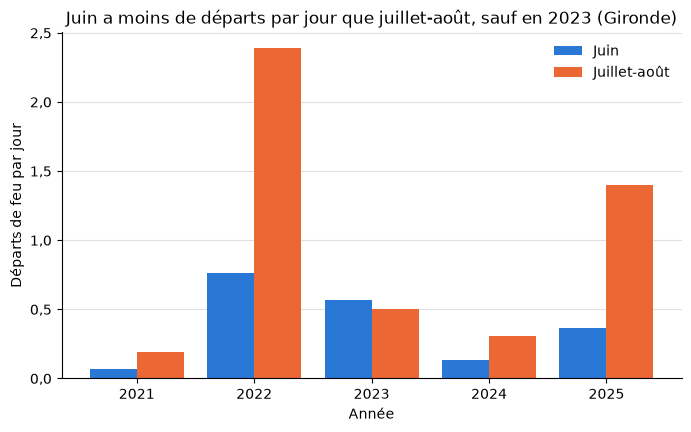

In [11]:
annees_juin_plus_fort = [str(a) for a in k1.index if k1.loc[a, "juin_par_jour"] > k1.loc[a, "juillet_aout_par_jour"]]
x = range(len(k1))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar([i - 0.2 for i in x], k1["juin_par_jour"], width=0.4, color=BLEU, label="Juin")
ax.bar([i + 0.2 for i in x], k1["juillet_aout_par_jour"], width=0.4, color=ORANGE, label="Juillet-août")
ax.set_xticks(list(x), k1.index.astype(str))
ax.yaxis.set_major_formatter(lambda valeur, _: fr(valeur))  # virgule décimale sur l'axe
ax.set(xlabel="Année", ylabel="Départs de feu par jour",
       title=f"Juin a moins de départs par jour que juillet-août, sauf en {', '.join(annees_juin_plus_fort)} (Gironde)")
ax.legend(frameon=False)
fig.savefig(FIGURES / "departs_par_jour.png", dpi=150, bbox_inches="tight")
plt.show()

Test de sensibilité : on recalcule le K1 médian sans 2024 (année incomplète, règle de qualité QR08), puis sur la **Gironde et les Landes** ensemble (communes 2026 des départements 33 et 40).

In [12]:
k1_gironde_landes = ratio_juin_juillet_aout(feux_2021_2025[feux_2021_2025["departement_2026"].isin(["33", "40"])], "size")
sensibilite = pd.DataFrame({"K1 médian (%)": [k1["ratio"].median(),
                                              k1["ratio"].drop(2024).median(),
                                              k1_gironde_landes["ratio"].median()]},
                           index=["Référence", "Sans 2024", "Gironde et Landes"])
sensibilite["Écart à la référence (points)"] = sensibilite["K1 médian (%)"] - sensibilite.loc["Référence", "K1 médian (%)"]

Ce graphique montre le K1 médian 2021-2025 dans les trois variantes du test : Gironde (référence), Gironde sans 2024, Gironde et Landes.

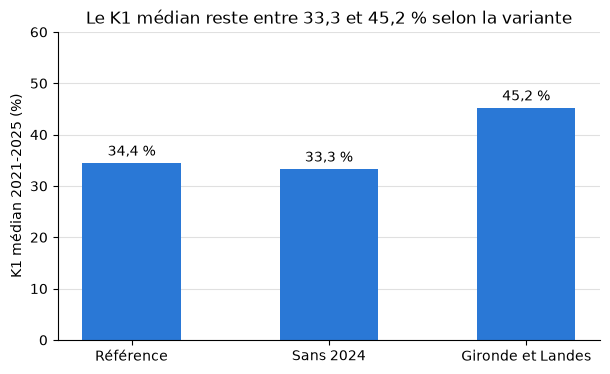

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
barres = ax.bar(sensibilite.index, sensibilite["K1 médian (%)"], color=BLEU, width=0.5)
ax.bar_label(barres, labels=[fr(v) + " %" for v in sensibilite["K1 médian (%)"]], padding=3)
ax.set(ylim=(0, 60), ylabel="K1 médian 2021-2025 (%)",
       title=f"Le K1 médian reste entre {fr(sensibilite['K1 médian (%)'].min())} et "
             f"{fr(sensibilite['K1 médian (%)'].max())} % selon la variante")
fig.savefig(FIGURES / "sensibilite_k1.png", dpi=150, bbox_inches="tight")
plt.show()

On calcule K2, le même ratio journalier sur la surface brûlée (ha) en **Gironde**, avec et sans les feux de plus de 1 000 ha (paramètre de la fiche K2), puis K4 : part des feux de plus de 1 ha en juin, moins la même part en juillet-août, en points.

In [14]:
k2 = ratio_juin_juillet_aout(feux_gironde, "sum")["ratio"]
k2_hors_grands_feux = ratio_juin_juillet_aout(feux_gironde[feux_gironde["surface_ha"] <= 1000], "sum")["ratio"]
part_plus_de_1ha = (feux_gironde.assign(plus_de_1ha=feux_gironde["surface_ha"] > 1)
                    .pivot_table(index="annee", columns="periode", values="plus_de_1ha", aggfunc="mean") * 100)
k4 = part_plus_de_1ha["juin"] - part_plus_de_1ha["juillet_aout"]
tableau_k2_k4 = pd.DataFrame({"K2 (%)": k2, "K2 hors feux > 1 000 ha (%)": k2_hors_grands_feux,
                              "Feux > 1 ha en juin (%)": part_plus_de_1ha["juin"],
                              "Feux > 1 ha en juillet-août (%)": part_plus_de_1ha["juillet_aout"], "K4 (points)": k4})
tableau_k2_k4.index.name = "Année"

Ce tableau montre K2 et K4 par année en **Gironde**.

In [15]:
tableau_k2_k4.style.format(precision=1, decimal=",")

,K2 (%),K2 hors feux > 1 000 ha (%),Feux > 1 ha en juin (%),Feux > 1 ha en juillet-août (%),K4 (points)
Année,,,,,
2021,"8,4","8,4","0,0","16,7","-16,7"
2022,"0,2","23,0","8,7","23,6","-15,0"
2023,"63,1","63,1","5,9","9,7","-3,8"
2024,"62,8","62,8","25,0","26,3","-1,3"
2025,"1,7","1,7","0,0","23,0","-23,0"


## Résultats pour la partie E

Les tableaux ci-dessous reprennent la partie E (et les valeurs de K2 et K4 de la partie D) de `G14_Atelier1_KPI.md`, au même format. La colonne « Conclusion » donne ici l'écart chiffré à la référence ; sa rédaction est dans la fiche.

In [16]:
motif = (f"aucun ; {len(codes_rattaches)} feu au code disparu rattaché par le COG "
         f"({', '.join(codes_rattaches['Code INSEE'] + ' -> ' + codes_rattaches['commune_2026'])})")
consolidation = pd.DataFrame({"Valeur": ["BDIFF + COG Insee", "Code INSEE rapporté à la commune 2026 · mois × année, Gironde",
                                         len(lignes_gironde), f"{perdues_non_rattachees + perdues_hors_gironde} (motif : {motif})"]},
                             index=["Sources jointes", "Clé et maille", "Lignes 2021-2025", "Lignes perdues à la jointure"])
consolidation.index.name = "Consolidation"
display(consolidation.style)
display(style_k1.hide(subset=["Départs en juillet-août"], axis="columns"))
print(f"Part des départs de juin due à l'année la plus forte : {fr(part_annee_forte)} % "
      f"({annee_forte}, {k1['juin'].max():.0f} départs sur {k1['juin'].sum():.0f}).")
sensibilite["Conclusion"] = ["référence"] + [f"{fr(e).replace('-', '−') if e < 0 else '+' + fr(e)} points"
                                            for e in sensibilite["Écart à la référence (points)"][1:]]
sensibilite.index.name = "Test de sensibilité"
display(sensibilite[["K1 médian (%)", "Conclusion"]].style.format(precision=1, decimal=",", subset=["K1 médian (%)"]))
valeurs_kpi = pd.DataFrame({"Valeur médiane 2021-2025": [k2.median(), k2_hors_grands_feux.median(), k4.median()],
                            "Unité": ["%", "%", "points"]},
                           index=["K2", "K2 hors feux > 1 000 ha", "K4"])
display(valeurs_kpi.style.format(precision=1, decimal=",", subset=["Valeur médiane 2021-2025"]))

,Valeur
Consolidation,
Sources jointes,BDIFF + COG Insee
Clé et maille,"Code INSEE rapporté à la commune 2026 · mois × année, Gironde"
Lignes 2021-2025,571
Lignes perdues à la jointure,0 (motif : aucun ; 1 feu au code disparu rattaché par le COG (33409 -> 33008))


periode,Départs en juin,Départs par jour en juillet-août (base),K1 (%)
Année,,,
2021,2,"0,19","34,4"
2022,23,"2,39","32,1"
2023,17,"0,50","113,3"
2024,4,"0,31","43,5"
2025,11,"1,40","26,1"
Moyenne,"11,4","0,96","49,9"
Médiane,11,"0,50","34,4"


Part des départs de juin due à l'année la plus forte : 40,4 % (2022, 23 départs sur 57).


,K1 médian (%),Conclusion
Test de sensibilité,,
Référence,"34,4",référence
Sans 2024,"33,3","−1,2 points"
Gironde et Landes,"45,2","+10,8 points"


,Valeur médiane 2021-2025,Unité
K2,"8,4",%
K2 hors feux > 1 000 ha,"23,0",%
K4,"-15,0",points
